In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.io
import matplotlib.pyplot as plt
import anndata as ad
from celltypist import models
import celltypist

In [1]:
def construct_anndata(file_path):
    
    barcodes = pd.read_csv(file_path / 'barcodes.tsv.gz', header=None)
    features = pd.read_csv(file_path / 'features.tsv.gz', header=None, sep="\t")

    spliced = scipy.io.mmread(file_path / 'spliced.mtx.gz').tocsc()
    unspliced = scipy.io.mmread(file_path / 'unspliced.mtx.gz').tocsc()
    # spanning = scipy.io.mmread(file_path / 'spanning.mtx.gz').tocsc()
    
    adata = ad.AnnData(X=spliced.T, dtype='float32')
    
    # barcodes
    adata.obs['barcodes'] = barcodes[0].values
    adata.obs_names = adata.obs['barcodes']
    # features
    adata.var['features'] = features[1].values
    adata.var_names = adata.var['features']
    # spliced and unspliced matrix for velocity
    adata.layers['spliced'] = spliced.T.tocsc()
    adata.layers['unspliced'] = unspliced.T.tocsc()
    
    adata.X = adata.layers["spliced"] + adata.layers["unspliced"]
    adata.layers['counts'] = adata.X.copy()
    
    return adata

def construct_anndata_norVelo(file_path):
    
    barcodes = pd.read_csv(file_path / 'barcodes.tsv.gz', header=None)
    features = pd.read_csv(file_path / 'features.tsv.gz', header=None, sep="\t")
    mtx = scipy.io.mmread(file_path / 'matrix.mtx.gz').tocsc()
    
    adata = ad.AnnData(X=mtx.T, dtype='float32')
    
    # barcodes
    adata.obs['barcodes'] = barcodes[0].values
    adata.obs_names = adata.obs['barcodes']
    # features
    adata.var['features'] = features[1].values
    adata.var_names = adata.var['features']
    
    adata.layers['counts'] = adata.X.copy()
    
    return adata

In [2]:
def pre_processing(adata):    
    adata.var['mt'] = adata.var_names.str.startswith('MT-')
    adata.var['rb'] = adata.var_names.str.contains('^RP[SL]')
    adata.var['hb'] = adata.var_names.str.contains('^HB[APS]')
    adata.var['hsp'] = adata.var_names.str.contains('^HSP')
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rb','hb','hsp'], percent_top=None, log1p=False, inplace=True)
    
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=1)
    
    adata = adata[adata.obs.total_counts > 300, :]
    adata = adata[adata.obs.total_counts < 30000, :]
    adata = adata[adata.obs.n_genes_by_counts <= 5000, :]
    adata = adata[adata.obs.pct_counts_mt < 10, :]
    adata = adata[adata.obs.pct_counts_hb < 5, :]
    
    return adata

In [5]:
from pathlib import Path

dir_path_1 = Path('/data/work/GZ_lab/ovarian/data/1120_L1/Solo.out/Velocyto/filtered/')
dir_path_2 = Path('/data/work/GZ_lab/ovarian/data/1120_L2/1120-L-2/Solo.out/Velocyto/filtered/')
L1 = construct_anndata(dir_path_1)
L2 = construct_anndata(dir_path_2)

In [6]:
print(L1)
print(L2)

AnnData object with n_obs × n_vars = 3209 × 38606
    obs: 'barcodes'
    var: 'features'
    layers: 'spliced', 'unspliced', 'counts'
AnnData object with n_obs × n_vars = 2751 × 38606
    obs: 'barcodes'
    var: 'features'
    layers: 'spliced', 'unspliced', 'counts'


In [7]:
L1.obs_names = [f"{bc}_L1" for bc in L1.obs_names]
L2.obs_names = [f"{bc}_L2" for bc in L2.obs_names]

In [8]:
L1.var_names_make_unique()
L2.var_names_make_unique()

In [9]:
dir_path_3 = Path('/data/work/GZ_lab/ovarian/data/GSE184880/selected_sample/')
nor_sample = construct_anndata_norVelo(dir_path_3)

In [10]:
nor_sample

AnnData object with n_obs × n_vars = 6370 × 27984
    obs: 'barcodes'
    var: 'features'
    layers: 'counts'

In [11]:
nor_sample.var_names_make_unique()

In [12]:
adata = sc.concat([L1, L2, nor_sample], label='batch', keys=["1120 L1", "1120 L2", 'Normal'])

In [13]:
adata

AnnData object with n_obs × n_vars = 12330 × 21204
    obs: 'barcodes', 'batch'
    layers: 'counts'

In [14]:
adata = pre_processing(adata)

In [15]:
adata

View of AnnData object with n_obs × n_vars = 8729 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: 'counts'

... storing 'barcodes' as categorical


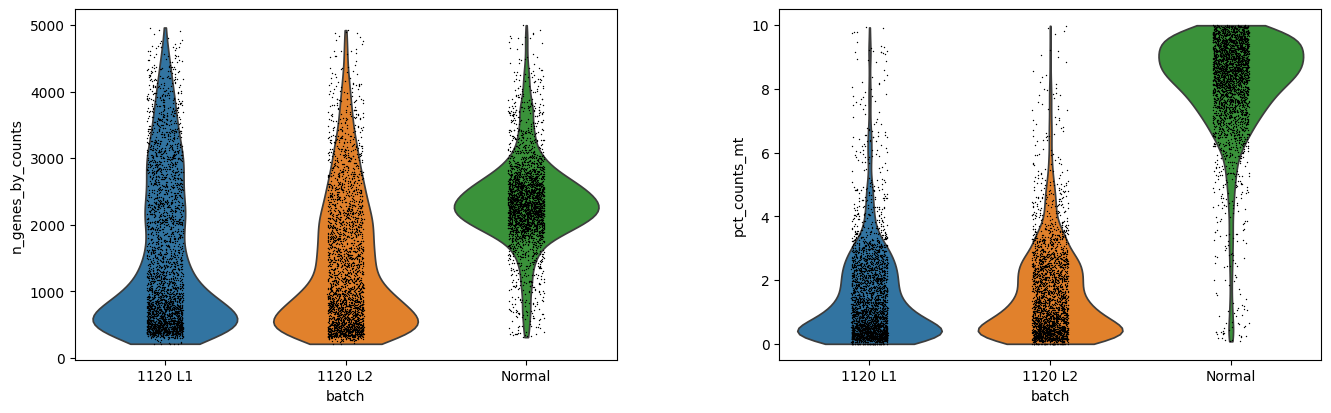

In [16]:
sc.pl.violin(adata, ["n_genes_by_counts", "pct_counts_mt"], multi_panel=True, groupby="batch")

In [17]:
adata.obs.groupby("batch")['n_genes'].median()

batch
1120 L1    1081.0
1120 L2    1072.0
Normal     2316.0
Name: n_genes, dtype: float64

In [18]:
adata.obs.groupby("batch")['barcodes'].count()

batch
1120 L1    3106
1120 L2    2673
Normal     2950
Name: barcodes, dtype: int64

In [19]:
adata.write_h5ad("./data/scncc_and_no-cancer.h5ad")

In [20]:
adata = sc.read_h5ad('./data/scncc_and_no-cancer.h5ad')

In [21]:
adata.obs['group'] = ["Normal" if i == "Normal" else "Cancer" for i in adata.obs['batch']]

In [22]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

In [23]:
adata

AnnData object with n_obs × n_vars = 8729 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'batch_colors', 'log1p'
    layers: 'counts'

In [24]:
model = models.Model.load(model = '/data/work/GZ_lab/ovarian/model/Immune_All_High.pkl')
predictions = celltypist.annotate(adata, model = model, majority_voting=True)

🔬 Input data has 8729 cells and 18939 genes
🔗 Matching reference genes in the model
🧬 5403 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Can not detect a neighborhood graph, will construct one before the over-clustering
/usr/local/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


In [25]:
adata.obs['predicted_celltype'] = predictions.predicted_labels.loc[adata.obs_names]['majority_voting']

In [26]:
adata.obs['predicted_probability'] = predictions.probability_matrix.loc[adata.obs_names].max(axis=1)

In [27]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=3000,
    layer="counts",
    min_mean=0.0125,
    max_mean=3,
    min_disp=0.5,
    flavor="seurat_v3",
    batch_key="batch",
    #span = 0.8 # prevent minimal span result to a error
)

In [28]:
sc.pp.regress_out(adata, ["total_counts", "pct_counts_mt", "n_genes_by_counts"], n_jobs=8)

... storing 'group' as categorical


In [29]:
sc.pp.pca(adata, svd_solver="arpack")

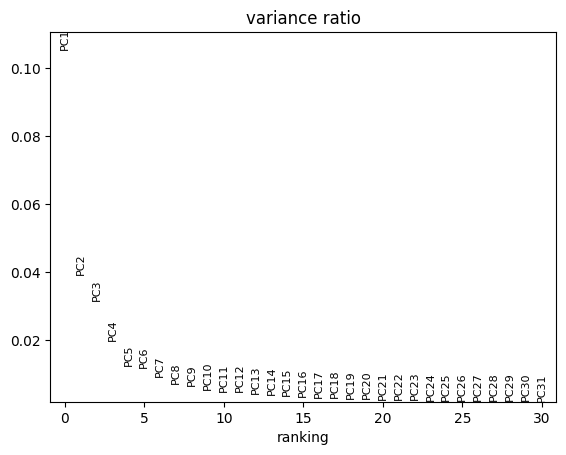

In [30]:
sc.pl.pca_variance_ratio(adata, n_pcs=30)

In [31]:
sc.external.pp.harmony_integrate(adata, key='batch')

2025-11-27 18:29:29,421 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
Computing initial centroids with sklearn.KMeans...
2025-11-27 18:29:38,191 - harmonypy - INFO - sklearn.KMeans initialization complete.
sklearn.KMeans initialization complete.
2025-11-27 18:29:38,400 - harmonypy - INFO - Iteration 1 of 10
Iteration 1 of 10
2025-11-27 18:29:44,627 - harmonypy - INFO - Iteration 2 of 10
Iteration 2 of 10
2025-11-27 18:29:49,923 - harmonypy - INFO - Converged after 2 iterations
Converged after 2 iterations


In [32]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca_harmony", random_state=26)

In [46]:
sc.tl.leiden(adata, resolution = 0.7, flavor = 'igraph', n_iterations=-1, random_state=26)

In [34]:
sc.tl.umap(adata, min_dist=0.3, random_state=0)

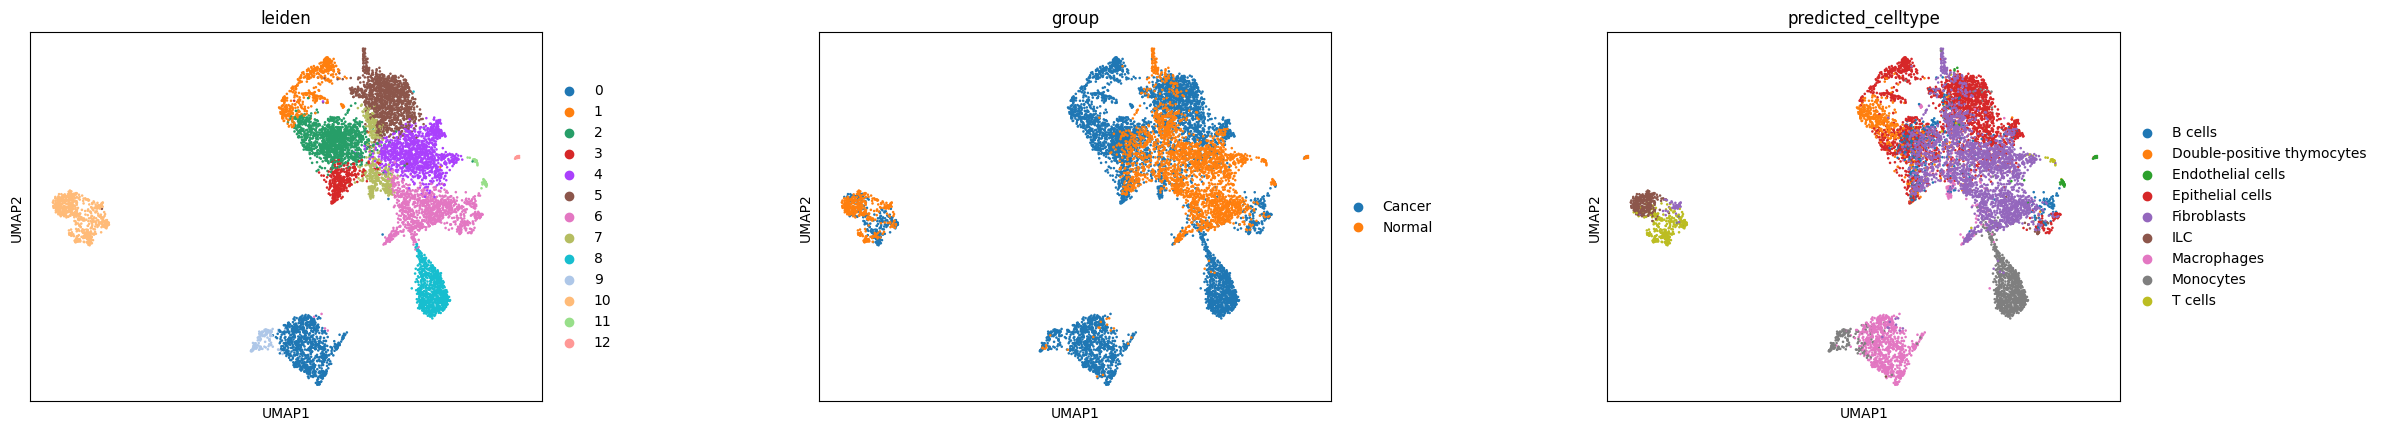

In [47]:
sc.pl.umap(adata, color=['leiden', 'group', 'predicted_celltype'], wspace=0.4)

In [36]:
adata.obs['predicted_celltype'].unique()

['Macrophages', 'Epithelial cells', 'Monocytes', 'Double-positive thymocytes', 'B cells', 'T cells', 'ILC', 'Endothelial cells', 'Fibroblasts']
Categories (9, object): ['B cells', 'Double-positive thymocytes', 'Endothelial cells', 'Epithelial cells', ..., 'ILC', 'Macrophages', 'Monocytes', 'T cells']

In [48]:
sc.tl.rank_genes_groups(adata, "leiden", mask_var="highly_variable", method="wilcoxon")

In [49]:
dfs = []
for g in adata.obs["leiden"].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, group=g)
    df["cluster"] = g
    dfs.append(df)
markers = pd.concat(dfs, ignore_index=True)

In [50]:
marker_df = markers.assign(row_index=markers.groupby('cluster').cumcount()).pivot_table(index='row_index', columns='cluster', values='names',  aggfunc='first')
marker_df.index.name = None
marker_df.columns.name = None
marker_df.loc[1:100].to_csv('scncc_marker.csv')

In [53]:
anno_mapping = {
    "0": "Macrophage",
    "1": "Epi_Neural_pro", # CDKN3, CENPF, KNTC2, MKI67, TOP2A
    "2": "Epi_Neuroendocrine",
    "3": "Fibroblast",
    "4": "Fibroblast",
    "5": "Epi_Neuron_like",
    "6": "Fibroblast",
    "7": "Fibroblast",
    "8": "Monocytes",
    "9": "Macrophage",
    "10": "NK/T cell",
    "11": "Endothelial cell",
    "12": "Endothelial cell"
}

adata.obs['anno_I'] = adata.obs['leiden'].replace(anno_mapping)

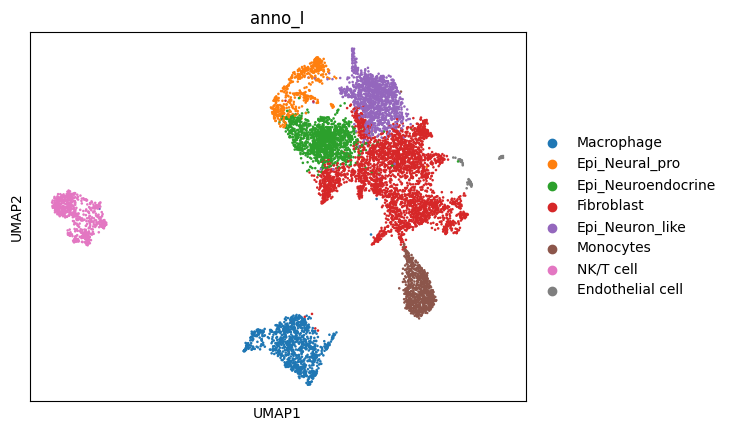

In [54]:
sc.pl.umap(adata, color='anno_I')

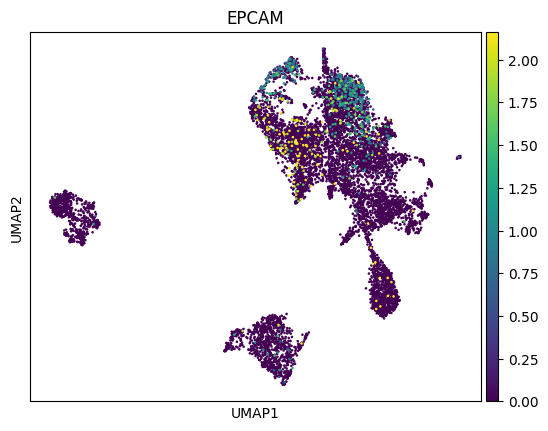

In [55]:
sc.pl.umap(adata, color='EPCAM', vmax='p99')

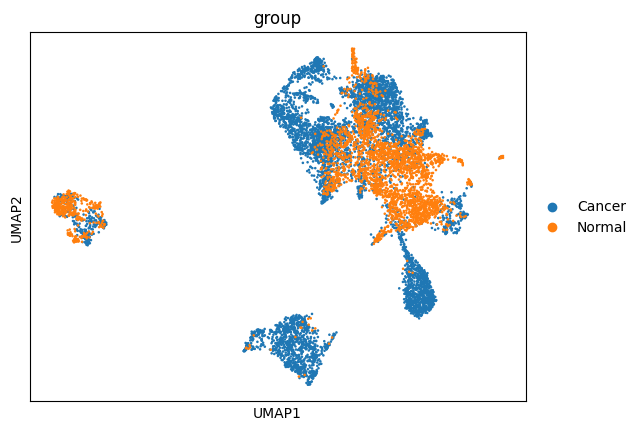

In [56]:
sc.pl.umap(adata, color='group')

In [57]:
adata.write_h5ad('./data/scncc_with_nocancer_anno.h5ad')

## plot

In [29]:
adata = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')

In [30]:
adata.obs['anno_I'] = adata.obs['anno_I'].cat.rename_categories(
    {
        'Epi_Neural_pro': 'Epi_1',
        'Epi_Neuroendocrine': 'Epi_2',
        'Epi_Neuron_like': 'Epi_3'
    }
)

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colors
import matplotlib as mpl

import matplotlib.font_manager as fm
font_dir = '/data/work/GZ_lab/ovarian/font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

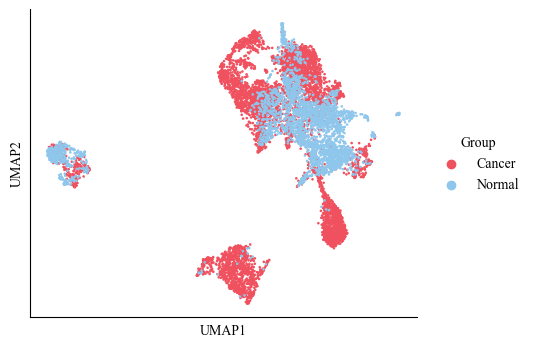

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))

color_dict = {'Cancer': '#f0515f', 'Normal': '#8ec6ec'}
sc.pl.umap(adata, color='group', show=False, ax=ax,
          palette=color_dict)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()

legend = ax.legend(handles, labels,
    title = 'Group',
    loc = 'center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon = False
)
ax.set_title('')
plt.savefig("./fig/fig1_data_batch_umap.pdf", format='pdf', bbox_inches='tight', transparent=False)
plt.show()

In [31]:
df = pd.crosstab(adata.obs['group'], adata.obs['anno_I']).div(pd.crosstab(adata.obs['group'], adata.obs['anno_I']).sum(axis=1), axis=0)

In [32]:
df

anno_I,Macrophage,Epi_1,Epi_2,Fibroblast,Epi_3,Monocytes,NK/T cell,Endothelial cell
group,,,,,,,,
Cancer,0.167849,0.088078,0.191037,0.188268,0.179616,0.136529,0.046548,0.002076
Normal,0.006441,0.000339,0.076610,0.665424,0.095593,0.001356,0.133898,0.020339


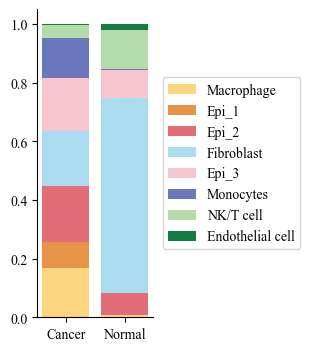

In [33]:
fig, ax = plt.subplots(figsize=(1.5, 4))

celltype2color = {
    'Macrophage': '#FDD379',
    'Epi_1': '#E68D3D',
    'Epi_3': '#F7C2CD',
    'Epi_2': '#E26472',
    'Fibroblast': '#A6DAEF',
    'Monocytes': '#6270B7',
    'NK/T cell': '#B0D9A5',
    'Endothelial cell': '#077535'
}


bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=celltype2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="", loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("./fig/fig1_cancer-normal_ratio.pdf", format='pdf', bbox_inches='tight', transparent=True)
plt.show()

In [34]:
df = pd.crosstab(adata.obs['anno_I'], adata.obs['group']).div(pd.crosstab(adata.obs['anno_I'], adata.obs['group']).sum(axis=1), axis=0)
df

group,Cancer,Normal
anno_I,,
Macrophage,0.980789,0.019211
Epi_1,0.998039,0.001961
Epi_2,0.830075,0.169925
Fibroblast,0.356604,0.643396
Epi_3,0.786364,0.213636
Monocytes,0.994956,0.005044
NK/T cell,0.405120,0.594880
Endothelial cell,0.166667,0.833333


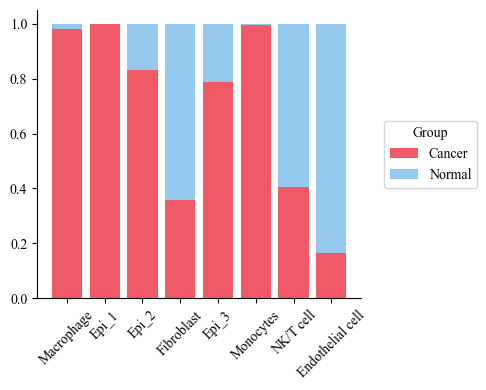

In [58]:
fig, ax = plt.subplots(figsize=(5, 4))

group2color = {'Cancer': '#f0515f', 'Normal': '#8ec6ec'}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=group2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()
labels = ['normal' if l == 'non-cancer' else l for l in labels]

legend = ax.legend(handles, labels,
    title = 'Group',
    loc ='center left',
    bbox_to_anchor=(1.05, 0.5),
    frameon = True)
                   
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("./fig/fig1_cancervsnormal_ratio.pdf", format='pdf', bbox_inches='tight', transparent=True)
plt.show()

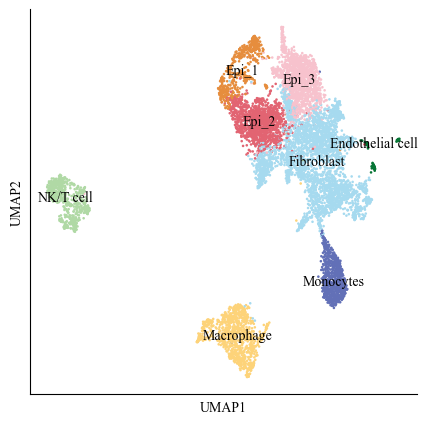

In [35]:
fig, ax = plt.subplots(figsize=(5, 5))
sc.pl.umap(adata, color='anno_I', show=False, ax=ax, legend_loc='on data', palette=celltype2color)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
ax.set_title('')
plt.savefig("./fig/fig1_anno_umap.pdf", format='pdf', bbox_inches='tight', transparent=True)
plt.show()

In [36]:
marker_dict = {
    "Epithelial cell": ["EPCAM", "KRT8", "KRT18"],
    "Proliferative": ["CDKN3", "CENPF", "MKI67", "TOP2A", "UBE2C"],
    "Neuroendocrine": ["CHGA", "SYP", "NCAM1", "INSM1", "SSTR2"],
    "Neuron": ["MAP1B", "SYT1", "LSAMP", "NRXN1", "RUNX1T1"],
    "Fibroblast": ["COL1A1", "COL1A2", "COL3A1"],
    "Endothelial cell": ["FLT1", "KDR", "LDB2"],
    "NK/T cell": ["CD3D", 'CD3G', "NKG7", "GZMB"],
    "Monocytes": ["S100A9", "S100A8"],    
    "Macrophage": ["AIF1", "CD14", "CD83"],
}

In [41]:
cell_plot = ["Epi_1", "Epi_2", "Epi_3",
            "Fibroblast", "Endothelial cell",
            "NK/T cell", "Monocytes", "Macrophage"]

In [42]:
adata.obs['anno_I_plot'] = pd.Categorical(
    adata.obs['anno_I'],
    categories=cell_plot,
    ordered=True
)

In [43]:
from matplotlib import colors

# Cancer': '#f0515f', 'Normal': '#8ec6ec'
custom_colors = ["#8ec6ec", "white", "#f0515f"]
cmap_custom = colors.LinearSegmentedColormap.from_list("my_gradient", custom_colors, N=128)

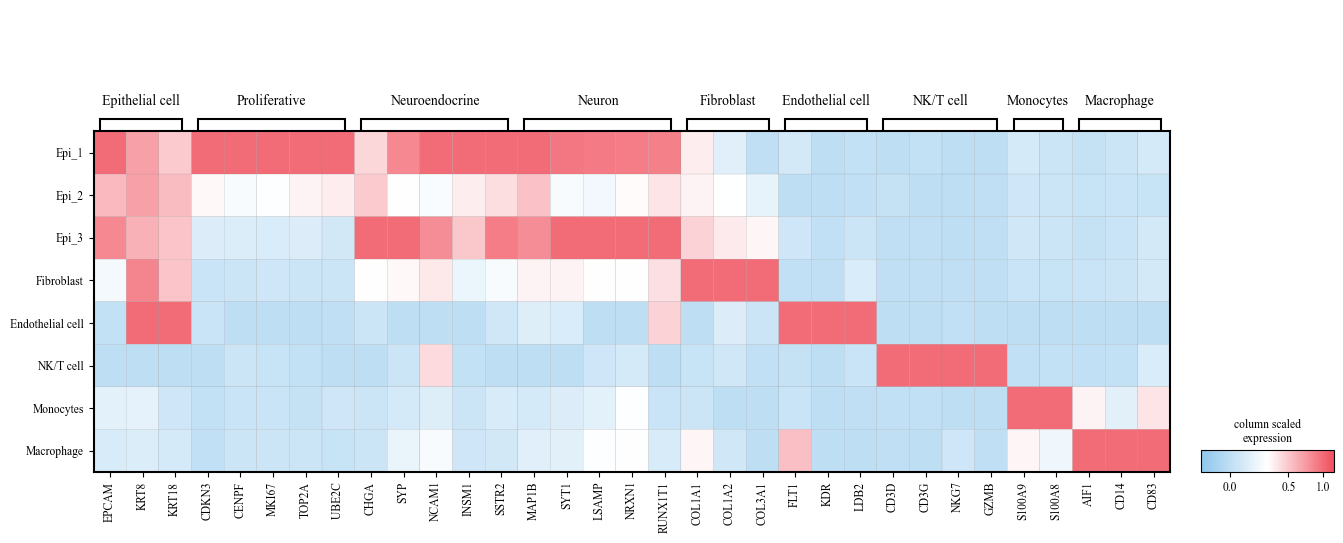

In [44]:
fig, ax = plt.subplots(figsize=(16, 6))

sc.pl.matrixplot(adata, marker_dict, 'anno_I_plot', cmap=cmap_custom, dendrogram=False, standard_scale="var", colorbar_title='column scaled\nexpression', show=False, ax=ax, vmax=1.15, vmin=-0.15, vcenter=0.2, var_group_rotation=0)

ax_list = [a for a in fig.axes if a.bbox.height < 0.15 * fig.bbox.height]
#for a in ax_list:
#    a.set_visible(False)
plt.savefig('./fig/fig1_marker_expression.pdf', format='pdf', bbox_inches='tight', transparent=True)

categories: Macrophage, Epi_Neural_pro, Epi_Neuroendocrine, etc.
var_group_labels: Epithelial cell, Proliferative, Neuroendocrine, etc.


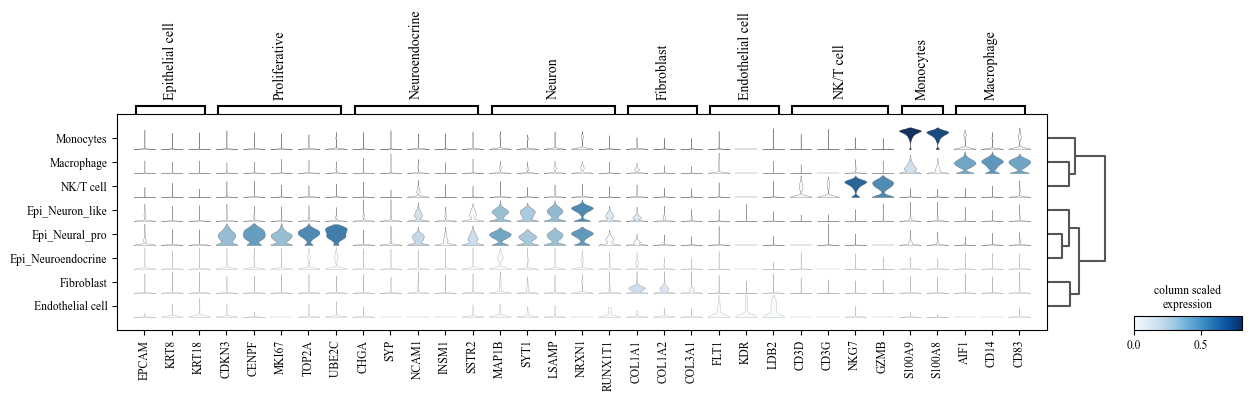

In [137]:
sc.pl.stacked_violin(adata, marker_dict, groupby='anno_I', dendrogram=True, standard_scale="var", colorbar_title='column scaled\nexpression',)

In [45]:
func_marker_dict = {
    "Classic": ['SYP', 'CHGA', 'CHGB', 'ENO2', 'NCAM1'],
    "Somatostain": ['SSTR1', 'SSTR2', 'SSTR3'],
    "TF": ['ASCL1', 'ASCL2', 'YAP1', 'TFF3'],
    "Proliferation": ['AURKA', 'BIRC5', 'CCNB1', 'CDC20', 'CDC6', 'CENPF', 'CEP55', 'EXO1', 'MKI67', 'KIF2C', 'MELK', 'MYBL2', 'NDC80', 'ORC6', 'PTTG1', 'RRM2', 'TYMS', 'UBE2C']
}

In [46]:
adata.obs['plot_group'] = adata.obs['group'].astype(str) + '-' + adata.obs['anno_I'].astype(str)

In [47]:
adata.obs['plot_group'].unique()

array(['Cancer-Macrophage', 'Cancer-Epi_1', 'Cancer-Epi_2',
       'Cancer-Epi_3', 'Cancer-Fibroblast', 'Cancer-Monocytes',
       'Cancer-NK/T cell', 'Cancer-Endothelial cell', 'Normal-Fibroblast',
       'Normal-Epi_2', 'Normal-Epi_3', 'Normal-NK/T cell',
       'Normal-Macrophage', 'Normal-Endothelial cell', 'Normal-Monocytes',
       'Normal-Epi_1'], dtype=object)

In [48]:
plot_order = [
    "Cancer-Epi_1", "Normal-Epi_1",
    "Cancer-Epi_2", "Normal-Epi_2",
    "Cancer-Epi_3", "Normal-Epi_3",
    "Cancer-Fibroblast", "Normal-Fibroblast",
    "Cancer-Endothelial cell", "Normal-Endothelial cell",
    "Cancer-Macrophage", "Normal-Macrophage",
    "Cancer-Monocytes", "Normal-Monocytes",
    "Cancer-NK/T cell", "Normal-NK/T cell"
             ]

In [49]:
for i in plot_order:
    if i not in adata.obs['plot_group'].unique():
        print(i)

In [50]:
adata.obs['plot_group'] = pd.Categorical(
    adata.obs['plot_group'],
    categories=plot_order,
    ordered=True
)

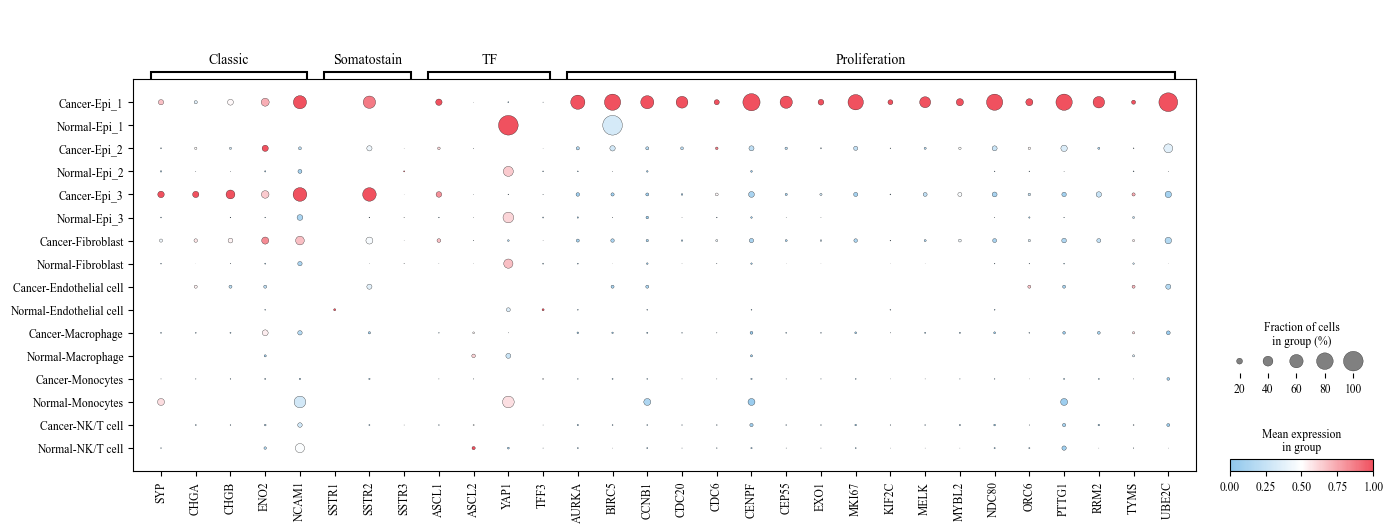

In [51]:
fig, ax = plt.subplots(figsize=(16, 6))
sc.pl.dotplot(adata, func_marker_dict, "plot_group", dendrogram=False, standard_scale='var', show=False, cmap=cmap_custom,ax=ax, var_group_rotation=0)
plt.savefig('./fig/fig1_func_marker_expression.pdf', format='pdf', bbox_inches='tight', transparent=True)

In [52]:
clinic_func_dict = {
    "Clinical": ['SYP', 'CHGA'],
    "TF": ['ASCL1', 'ASCL2']
}

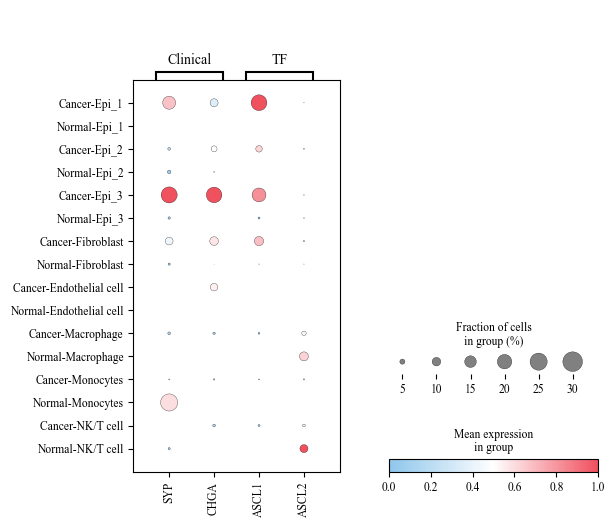

In [53]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.dotplot(adata, clinic_func_dict, "plot_group", dendrogram=False, standard_scale='var', show=False, cmap=cmap_custom, var_group_rotation=0, ax=ax)

plt.savefig('./fig/fig2_clinical_marker_expression.pdf', format='pdf', bbox_inches='tight', transparent=True)

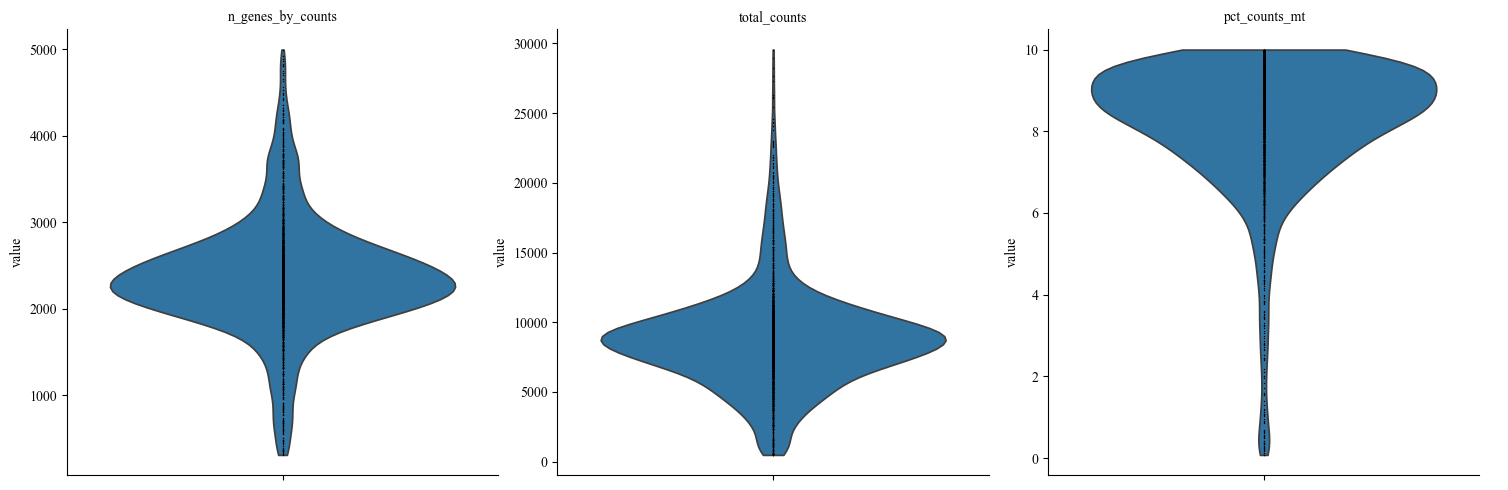

In [17]:
sc.pl.violin(adata[adata.obs['group'] == "Normal"], ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True, jitter=False, show=False)
plt.savefig('./fig/figs1_Normal_quanlity_contral.pdf', format='pdf', bbox_inches='tight', transparent=True)

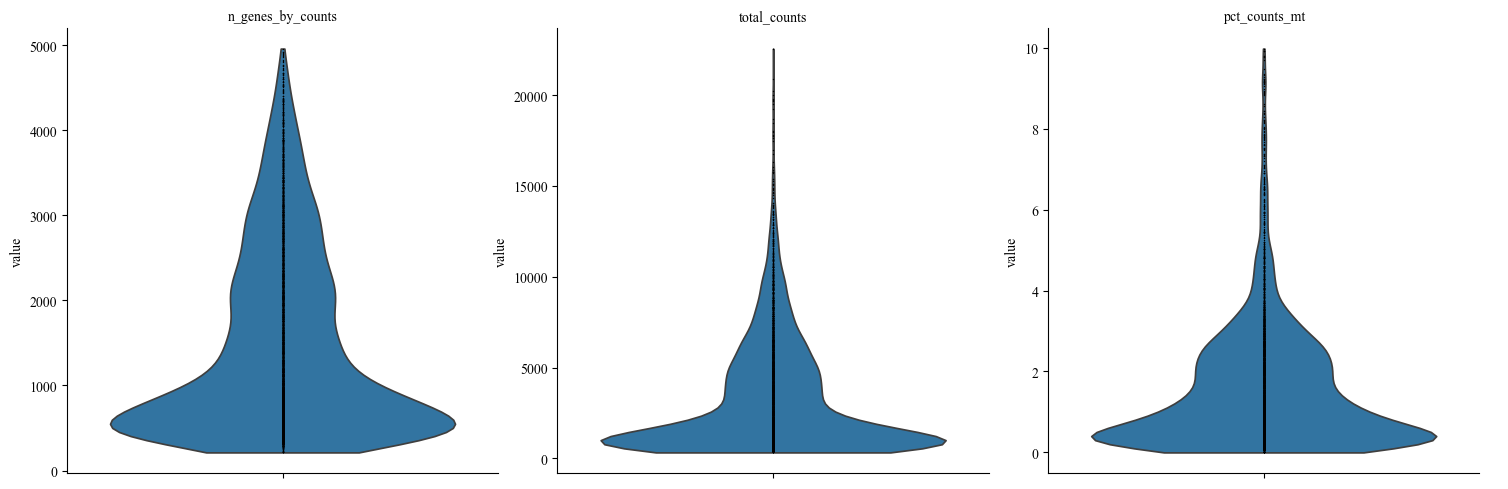

In [18]:
sc.pl.violin(adata[adata.obs['group'] == "Cancer"], ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True, jitter=False, show=False)
plt.savefig('./fig/figs1_Cancer_quanlity_contral.pdf', format='pdf', bbox_inches='tight', transparent=True)

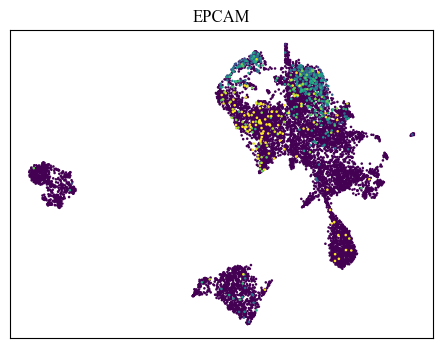

In [5]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='EPCAM', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Epthelial.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

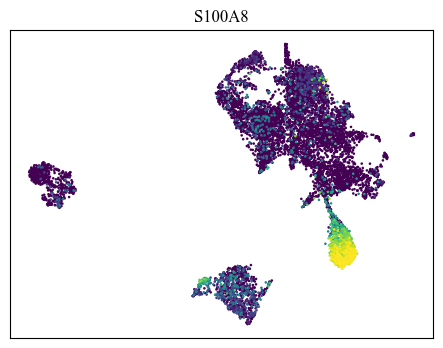

In [6]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='S100A8', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Monocyte.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

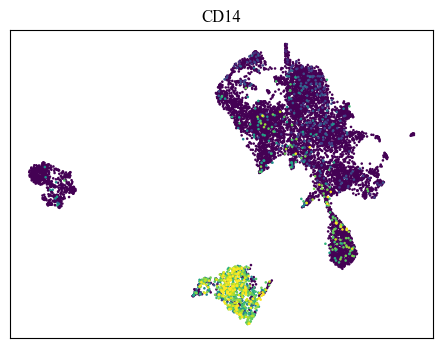

In [7]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='CD14', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Macrophage.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

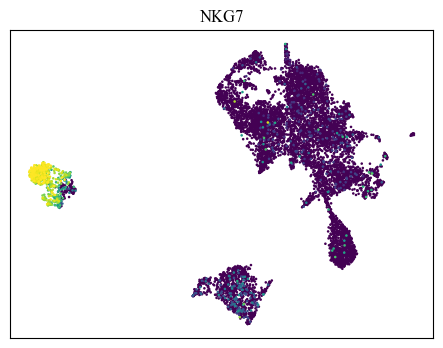

In [8]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='NKG7', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_NK.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

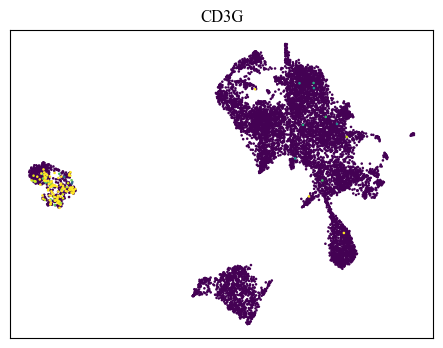

In [9]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='CD3G', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_T.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

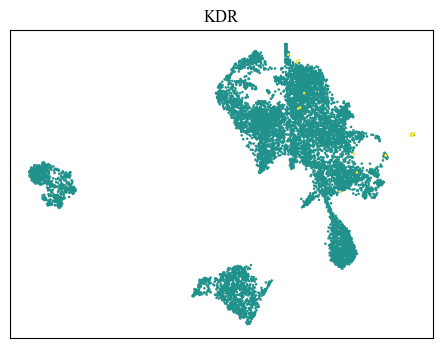

In [10]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color='KDR', vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Endothelial.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

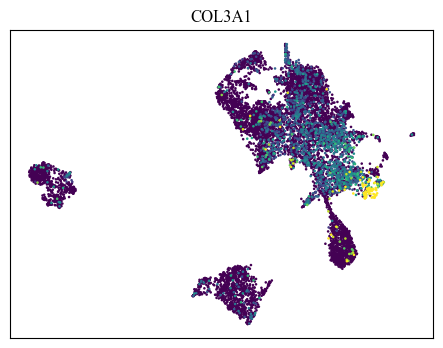

In [11]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color=['COL3A1'], vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Fibroblast.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

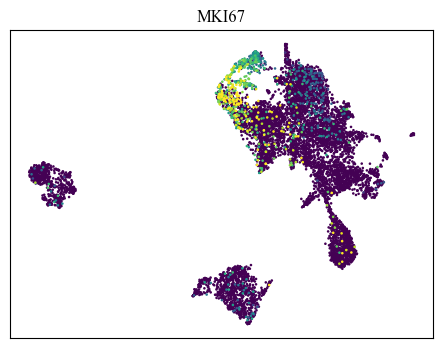

In [12]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color=['MKI67'], vmax='p99', vmin='p1', show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Proliferative.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

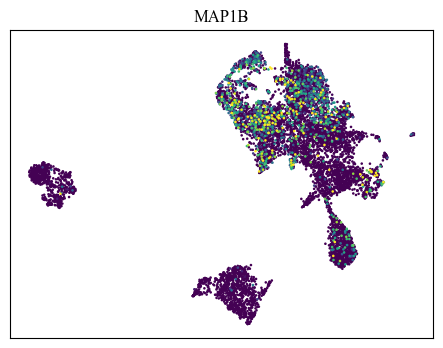

In [13]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color=['MAP1B'], vmax=3.25, vmin=2, show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Neuron.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

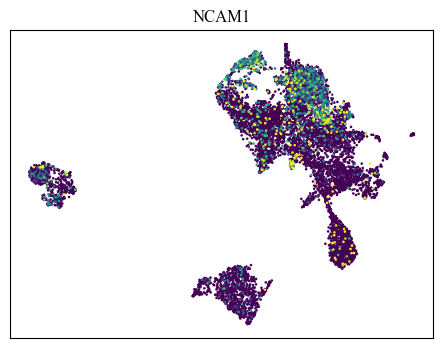

In [14]:
plt.rcParams['figure.figsize'] = (6, 4)

sc.pl.umap(adata, color=['NCAM1'], vmax='p99', vmin=1, show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_Endocrine.png', format='png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()

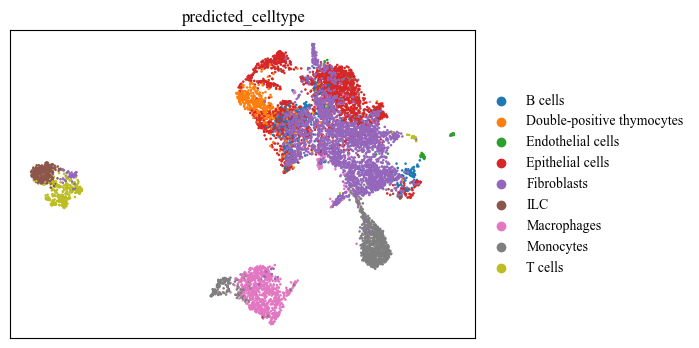

In [15]:
sc.pl.umap(adata, color=['predicted_celltype'], show=False)
ax = plt.gca()
ax.set_xlabel('')
ax.set_ylabel('')
#plt.gcf().axes[-1].remove()
plt.savefig('./fig/figs1_prediction_result.png', format='png', dpi=600, bbox_inches='tight', transparent=True)

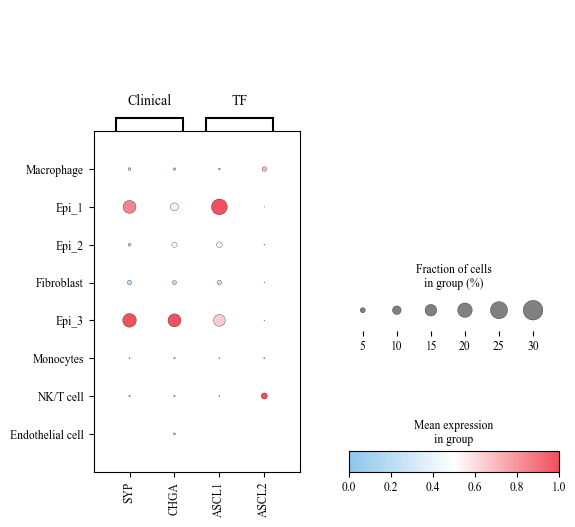

In [54]:
fig, ax = plt.subplots(figsize=(6, 6))

sc.pl.dotplot(adata, clinic_func_dict, "anno_I", dendrogram=False, standard_scale='var', show=False, cmap=cmap_custom, var_group_rotation=0, ax=ax)

plt.savefig('./fig/figs1_clinical_marker_expression.pdf', format='pdf', bbox_inches='tight', transparent=True)

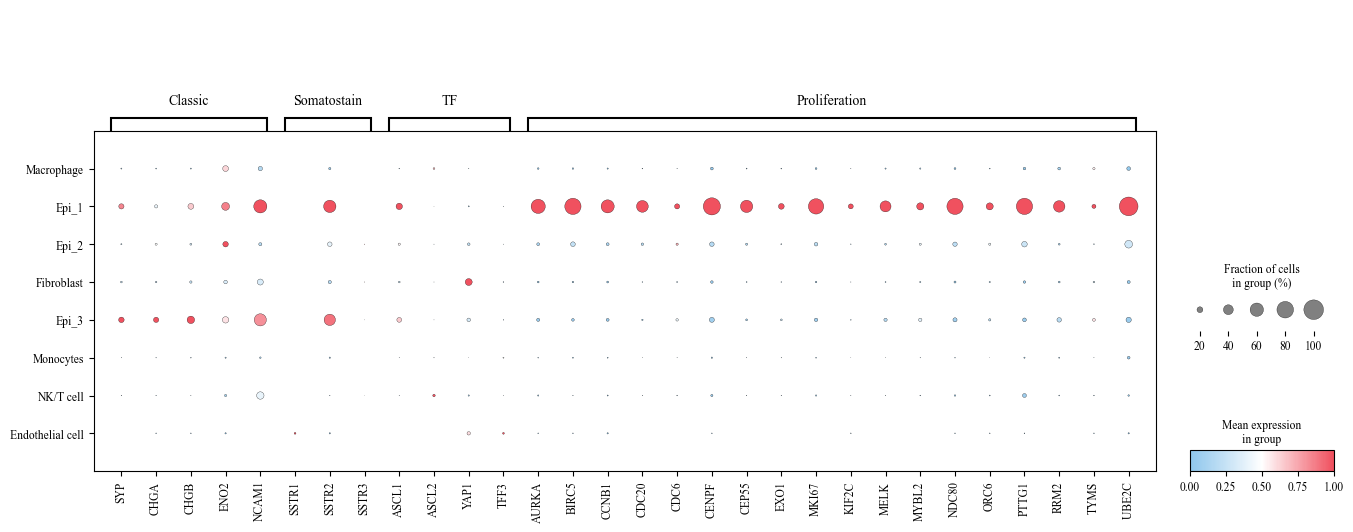

In [55]:
fig, ax = plt.subplots(figsize=(16, 6))
sc.pl.dotplot(adata, func_marker_dict, "anno_I", dendrogram=False, standard_scale='var', show=False, cmap=cmap_custom,ax=ax, var_group_rotation=0)
plt.savefig('./fig/figs1_func_marker_expression.pdf', format='pdf', bbox_inches='tight', transparent=True)

In [16]:
df = pd.crosstab(adata.obs['predicted_celltype'], adata.obs['group']).div(pd.crosstab(adata.obs['predicted_celltype'], adata.obs['group']).sum(axis=1), axis=0)
df

group,Cancer,Normal
predicted_celltype,,
B cells,1.000000,0.000000
Double-positive thymocytes,1.000000,0.000000
Endothelial cells,0.178571,0.821429
Epithelial cells,1.000000,0.000000
Fibroblasts,0.000000,1.000000
ILC,0.355114,0.644886
Macrophages,1.000000,0.000000
Monocytes,0.983748,0.016252
T cells,0.572650,0.427350


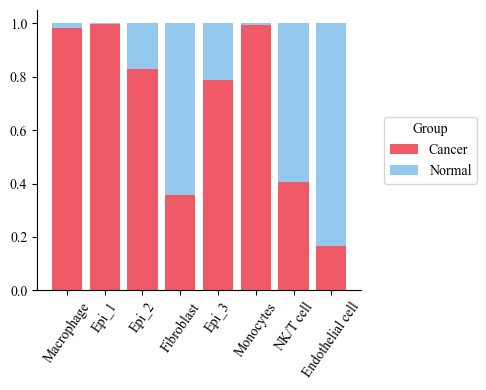

In [57]:
fig, ax = plt.subplots(figsize=(5, 4))

group2color = {'Cancer': '#f0515f', 'Normal': '#8ec6ec'}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=group2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()
labels = ['normal' if l == 'non-cancer' else l for l in labels]

legend = ax.legend(handles, labels,
    title = 'Group',
    loc ='center left',
    bbox_to_anchor=(1.05, 0.5),
    frameon = True)
                   
plt.xticks(rotation=55)
plt.tight_layout()
plt.savefig("./fig/figs1_Prediction_cancervsnormal_ratio.pdf", format='pdf', bbox_inches='tight', transparent=True)
plt.show()